In [7]:

# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the dataset
data_paths = [
    "data/winequality-red.csv",
    "../data/winequality-red.csv",
    "winequality-red.csv"
]

data_path = None

for path in data_paths:
    if os.path.exists(path):
        data_path = path
        break

# Upload dataset if it is not found
if data_path is None:
    from google.colab import files

    uploaded = files.upload()

    for filename in uploaded:
        if filename.endswith(".csv"):
            data_path = filename
            break

# Check dataset
if data_path is None:
    raise FileNotFoundError("Dataset not found!")

# Read dataset
df = pd.read_csv(data_path, sep=";")

# Create folder for saving charts
os.makedirs("reports", exist_ok=True)

# Display basic information
print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (1599, 12)

Dataset columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Missing values:
0

First 5 rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


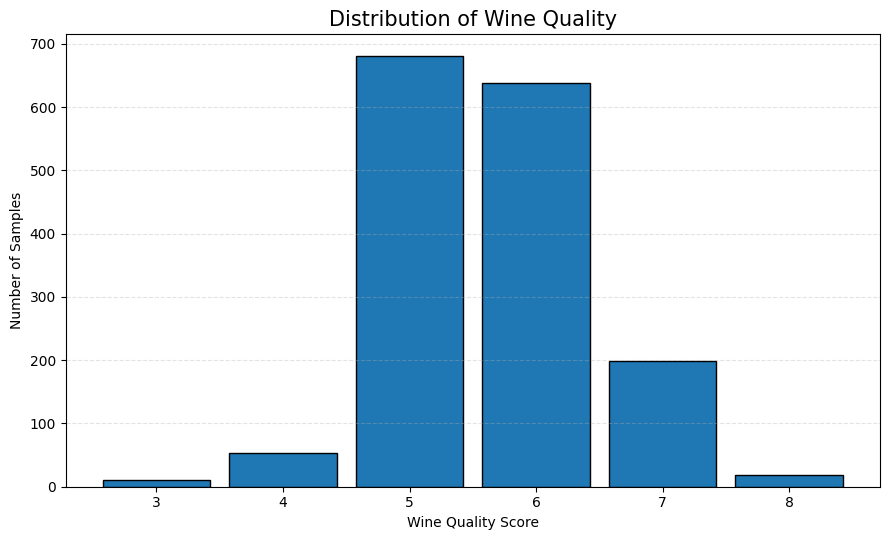

Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [8]:

# Plot Histogram
plt.figure(figsize=(9, 5.5))

bins = np.arange(
    df["quality"].min() - 0.5,
    df["quality"].max() + 1.5,
    1
)

plt.hist(
    df["quality"],
    bins=bins,
    edgecolor="black",
    rwidth=0.85
)

plt.title("Distribution of Wine Quality", fontsize=15)
plt.xlabel("Wine Quality Score")
plt.ylabel("Number of Samples")

plt.xticks(sorted(df["quality"].unique()))

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

# Save chart
plt.savefig(
    "reports/quality_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display quality distribution
print("Quality Distribution:")
print(df["quality"].value_counts().sort_index())


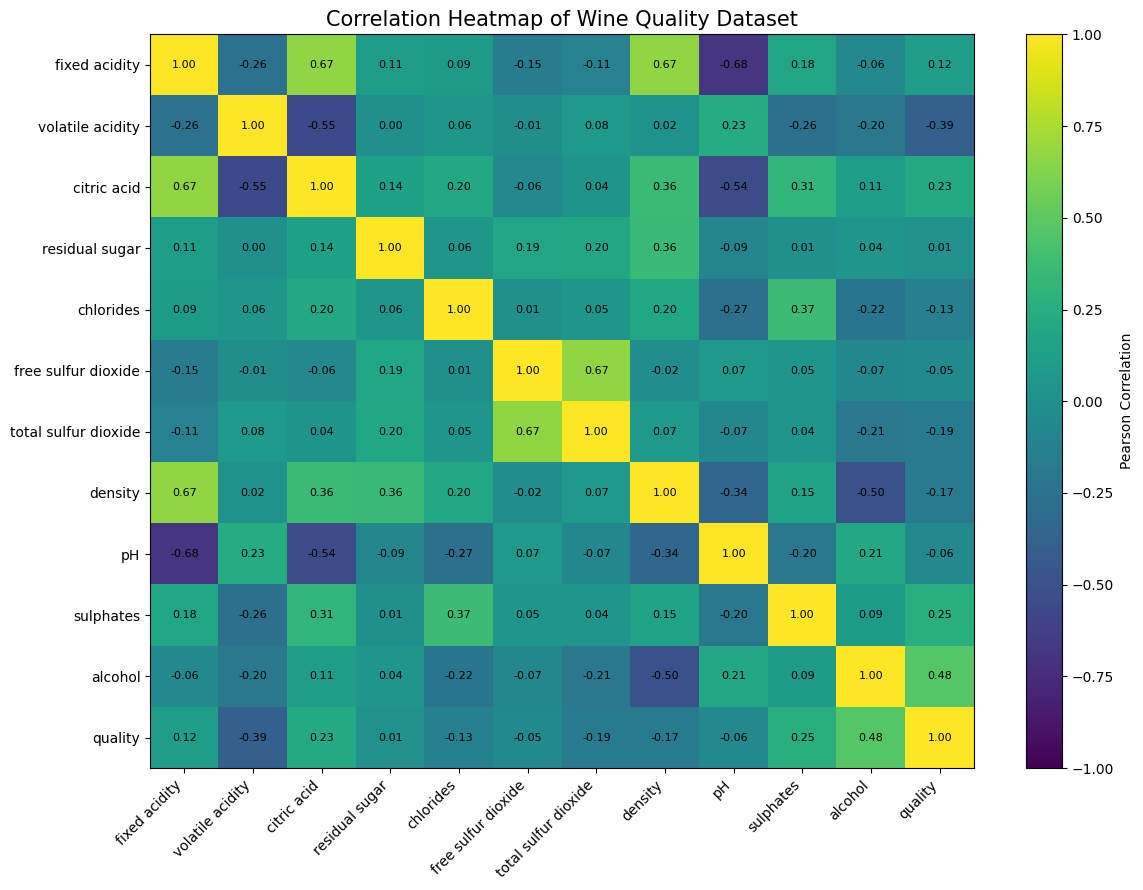

Correlation with Quality:
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


In [9]:

# Calculate correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Create heatmap
fig, ax = plt.subplots(figsize=(12, 9))

image = ax.imshow(
    correlation_matrix.values,
    aspect="auto",
    vmin=-1,
    vmax=1
)

# Set axis labels
ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation_matrix.index)

# Display correlation values
for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):

        value = correlation_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

ax.set_title(
    "Correlation Heatmap of Wine Quality Dataset",
    fontsize=15
)

fig.colorbar(
    image,
    ax=ax,
    label="Pearson Correlation"
)

fig.tight_layout()

# Save chart
plt.savefig(
    "reports/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display correlation with quality
print("Correlation with Quality:")

quality_corr = (
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

print(quality_corr)


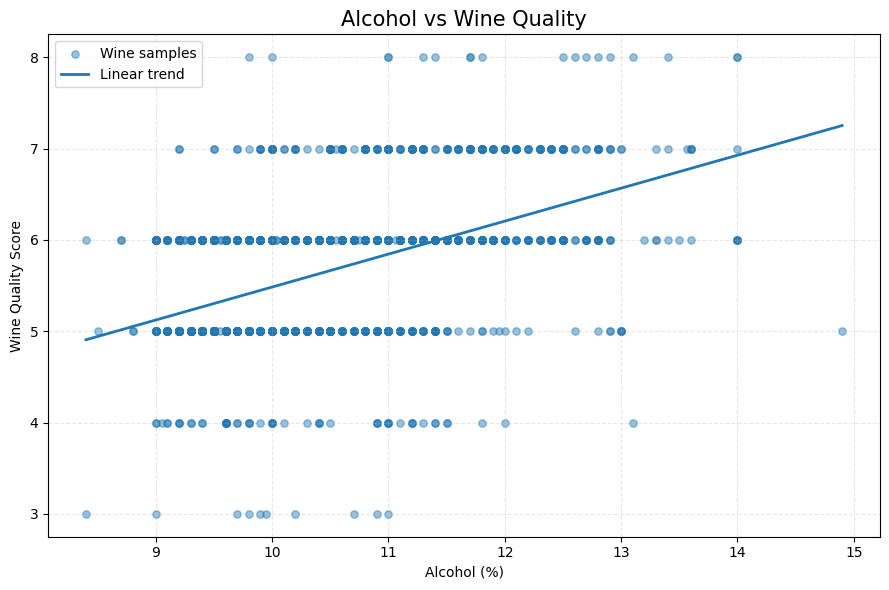

Number of samples: 1599
Alcohol range: 8.4 - 14.9
Quality range: 3 - 8
Pearson correlation: 0.4762


In [10]:

# Calculate Pearson correlation
correlation = df["alcohol"].corr(df["quality"])

# Calculate linear trend
slope, intercept = np.polyfit(
    df["alcohol"],
    df["quality"],
    1
)

x_line = np.linspace(
    df["alcohol"].min(),
    df["alcohol"].max(),
    100
)

y_line = slope * x_line + intercept

# Create Scatter Plot
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    df["alcohol"],
    df["quality"],
    alpha=0.45,
    s=28,
    label="Wine samples"
)

ax.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear trend"
)

ax.set_title("Alcohol vs Wine Quality", fontsize=15)
ax.set_xlabel("Alcohol (%)")
ax.set_ylabel("Wine Quality Score")

ax.set_yticks(sorted(df["quality"].unique()))

ax.grid(
    True,
    linestyle="--",
    alpha=0.3
)

ax.legend()
fig.tight_layout()

# Save chart
plt.savefig(
    "reports/alcohol_vs_quality_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display results
print("Number of samples:", len(df))
print("Alcohol range:", df["alcohol"].min(), "-", df["alcohol"].max())
print("Quality range:", df["quality"].min(), "-", df["quality"].max())

print("Pearson correlation:", round(correlation, 4))


In [11]:

print("========== EDA SUMMARY ==========")

print("\n1. Dataset Information")
print("Number of samples:", len(df))
print("Number of features:", len(df.columns) - 1)
print("Target variable: quality")

print("\n2. Quality Distribution")
print(df["quality"].value_counts().sort_index())

print("\n3. Top Correlations with Quality")

quality_corr = (
    df.corr(numeric_only=True)["quality"]
    .drop("quality")
    .sort_values(key=abs, ascending=False)
)

print(quality_corr)

print("\n4. Alcohol vs Quality")
print("Pearson correlation:", round(correlation, 4))

print("\n5. Generated Files")

for filename in [
    "quality_histogram.png",
    "correlation_heatmap.png",
    "alcohol_vs_quality_scatter.png"
]:
    path = os.path.join("reports", filename)

    if os.path.exists(path):
        print(filename, "- Created successfully")
    else:
        print(filename, "- Not found")

print("\nEDA completed!")


========== EDA SUMMARY ==========

1. Dataset Information
Number of samples: 1599
Number of features: 11
Target variable: quality

2. Quality Distribution
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

3. Top Correlations with Quality
alcohol                 0.476166
volatile acidity       -0.390558
sulphates               0.251397
citric acid             0.226373
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
fixed acidity           0.124052
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
Name: quality, dtype: float64

4. Alcohol vs Quality
Pearson correlation: 0.4762

5. Generated Files
quality_histogram.png - Created successfully
correlation_heatmap.png - Created successfully
alcohol_vs_quality_scatter.png - Created successfully

EDA completed!
